# HazeGuard-MY — Damage-cost tests

Tests and graphs for `pipeline/04_policy.py`. Run top to bottom (**Kernel → Restart & Run All**).
Every check prints `PASS`/`FAIL`, and the last cell lists them all and fails if any check failed.

| Section | What it does |
|---|---|
| 1 | Setup |
| 2 | Create the dataset, view it, summarise it |
| 3 | Data checks + haze graphs |
| 4 | Run the damage model |
| 5 | Output checks |
| 6 | Results graphs |
| 7 | Behaviour checks (clean air, dose–response) |
| 8 | Uncertainty (Monte Carlo) |
| 9 | Sensitivity (tornado) |
| 10 | Backtest vs mock truth |
| 11 | Realism check vs published estimates |
| 12 | Test summary |

> **The haze history, population and GDP are still dummy data** (calibrated to the real 2026 pattern, but generated).
> If `data/raw/pm25_daily_openmeteo.csv` exists, real PM2.5 replaces the dummy values for the dates it covers.
> Mortality is **off**: haze is treated as non-fatal.

Setup: `pip install -r pipeline/requirements.txt`, then `jupyter notebook tests/04_damage_tests.ipynb`.

## 1. Setup

In [1]:
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

# Find the repo root whether the notebook runs from tests/ or the root
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
spec = importlib.util.spec_from_file_location("policy", ROOT / "pipeline" / "04_policy.py")
policy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(policy)

# Chart style: light surface, recessive grid, fixed colours
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#c3c2b7"
BAND_COLOURS = {"good": "#0ca30c", "moderate": "#fab219", "unhealthy": "#ec835a",
                "very_unhealthy": "#d03b3b", "hazardous": "#7a1f1f"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": OTHER,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 9.5, "legend.frameon": False,
})
rm_m = mtick.FuncFormatter(lambda v, _: f"RM {v/1e6:,.0f} m")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

RESULTS = []
def check(name, condition, detail=""):
    """Record and print one test result."""
    ok = bool(condition)
    RESULTS.append({"test": name, "result": "PASS" if ok else "FAIL", "detail": detail})
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  —  {detail}" if detail else ""))
    return ok

print("Repo root:", ROOT)

Repo root: C:\Users\aryan\Documents\UoM Files\2nd Year\IBM DATATHON\ibm-larp


## 2. Create, view and summarise the dataset

Set `SAVE_MOCK = True` to also write the CSVs to `data/mock/damage/` (the model then reads them from there).
Change `VIEW_STATE` / `VIEW_ROWS` to look at a different state.

In [2]:
SAVE_MOCK = False
VIEW_STATE = "Sarawak"
VIEW_ROWS = 10

ref, haze, truth, source = policy.load_inputs(save_mock=SAVE_MOCK)
mock = policy.build_mock()          # pure mock, for the backtest and the real-vs-mock comparison
print("Data source:", source)
print(f"state_reference: {ref.shape}   haze_daily: {haze.shape}   "
      f"damage_costs_daily: {None if truth is None else truth.shape}")

[warn] data\mock\damage is from an older version (missing ['flights_scheduled', 'school_closed_share', 'stations_over_200']); using freshly generated mock data instead. Re-save with --save-mock to update the CSVs.


Data source: synthetic
state_reference: (16, 19)   haze_daily: (1008, 14)   damage_costs_daily: (1008, 11)


In [3]:
# State reference (one row per state)
ref[["state", "region", "population", "gdp_rm_bn", "employed", "students",
     "outdoor_worker_share", "agri_share", "tourism_share", "airport_flights_day"]]

,state,region,population,gdp_rm_bn,employed,students,outdoor_worker_share,agri_share,tourism_share,airport_flights_day
0,Johor,Peninsular,4180000,171.0,2094637,601912,0.208,0.12,0.05,90
1,Kedah,Peninsular,2200000,56.3,1055993,308323,0.252,0.18,0.04,40
2,Kelantan,Peninsular,1920000,28.0,975463,299017,0.289,0.20,0.03,30
3,Melaka,Peninsular,1050000,47.0,523113,160961,0.185,0.06,0.09,4
4,Negeri Sembilan,Peninsular,1230000,55.0,578401,189547,0.198,0.10,0.04,0
5,Pahang,Peninsular,1690000,61.0,859762,262988,0.307,0.25,0.05,12
6,Perak,Peninsular,2550000,89.0,1287244,380404,0.228,0.15,0.04,6
7,Perlis,Peninsular,300000,6.7,151562,45412,0.290,0.20,0.02,0
8,Pulau Pinang,Peninsular,1800000,122.0,849761,257032,0.147,0.02,0.07,110
9,Sabah,Borneo,3550000,89.0,1710610,505131,0.304,0.22,0.06,180


In [4]:
# Daily haze for one state
haze[haze.state == VIEW_STATE].head(VIEW_ROWS)

,date,state,pm25_ugm3,api_mean,api_max,stations_total,stations_unhealthy,stations_over_200,flights_scheduled,api_band,school_closed_share,school_closed,flights_disrupted,cloud_seeding_ops
630,2026-08-15,Sarawak,26.7,53.4,57.5,5,0,0,160,moderate,0.0,0,0,0
631,2026-08-16,Sarawak,25.7,51.5,61.8,5,0,0,160,moderate,0.0,0,0,0
632,2026-08-17,Sarawak,26.1,52.3,57.3,5,0,0,160,moderate,0.0,0,0,0
633,2026-08-18,Sarawak,31.5,62.9,73.2,5,0,0,160,moderate,0.0,0,0,0
634,2026-08-19,Sarawak,34.7,69.4,74.4,5,0,0,160,moderate,0.0,0,0,0
635,2026-08-20,Sarawak,40.7,78.6,99.1,5,0,0,160,moderate,0.0,0,0,0
636,2026-08-21,Sarawak,45.3,85.4,91.7,5,2,0,160,moderate,0.0,0,0,0
637,2026-08-22,Sarawak,65.2,113.6,131.6,5,4,0,160,unhealthy,0.0,0,0,0
638,2026-08-23,Sarawak,78.8,131.7,143.2,5,5,0,160,unhealthy,0.0,0,0,0
639,2026-08-24,Sarawak,102.3,161.8,167.8,5,5,0,160,unhealthy,0.0,0,1,0


In [5]:
# Summary statistics for the haze table
haze.describe().T[["mean", "min", "max"]].round(1)

,mean,min,max
pm25_ugm3,33.3,8.8,205.7
api_mean,61.7,17.5,255.7
api_max,71.8,20.1,301.5
stations_total,4.0,2.0,7.0
stations_unhealthy,0.6,0.0,7.0
stations_over_200,0.0,0.0,5.0
flights_scheduled,89.5,0.0,700.0
school_closed_share,0.0,0.0,1.0
school_closed,0.0,0.0,1.0
flights_disrupted,0.4,0.0,24.0


## 3. Data checks

In [6]:
dates = pd.to_datetime(haze.date)
check("All 16 states in the state table", set(ref.state) == set(policy.STATE_NAMES), f"{ref.state.nunique()} states")
check("All 16 states in the haze table", set(haze.state) == set(policy.STATE_NAMES))
check("No missing values (state table)", not ref.isna().any().any())
check("No missing values (haze table)", not haze.isna().any().any())
check("One row per state per day", not haze.duplicated(["state", "date"]).any())
check("No gaps in the dates", haze.groupby("state").date.nunique().eq(dates.dt.normalize().nunique()).all(),
      f"{dates.min():%d %b} → {dates.max():%d %b %Y}")
check("PM2.5 within 0–500 µg/m3", haze.pm25_ugm3.between(0, 500).all(),
      f"max {haze.pm25_ugm3.max():.0f}")
check("API within 0–500", haze.api_max.between(0, 500).all())
check("Worst station API ≥ state average API", (haze.api_max >= haze.api_mean - 0.1).all())
check("School-closure share within 0–1", haze.school_closed_share.between(0, 1).all())
check("Sarawak has the worst peak (as in the real 2026 data)",
      haze.groupby("state").pm25_ugm3.max().idxmax() == "Sarawak")

PASS  All 16 states in the state table  —  16 states
PASS  All 16 states in the haze table
PASS  No missing values (state table)
PASS  No missing values (haze table)
PASS  One row per state per day
PASS  No gaps in the dates  —  15 Aug → 16 Oct 2026
PASS  PM2.5 within 0–500 µg/m3  —  max 206
PASS  API within 0–500
PASS  Worst station API ≥ state average API
PASS  School-closure share within 0–1
PASS  Sarawak has the worst peak (as in the real 2026 data)


True

### PM2.5 over time
Sarawak (Borneo wave, late Aug) and the Klang Valley (west-coast wave, mid-Oct) highlighted; other states in grey.

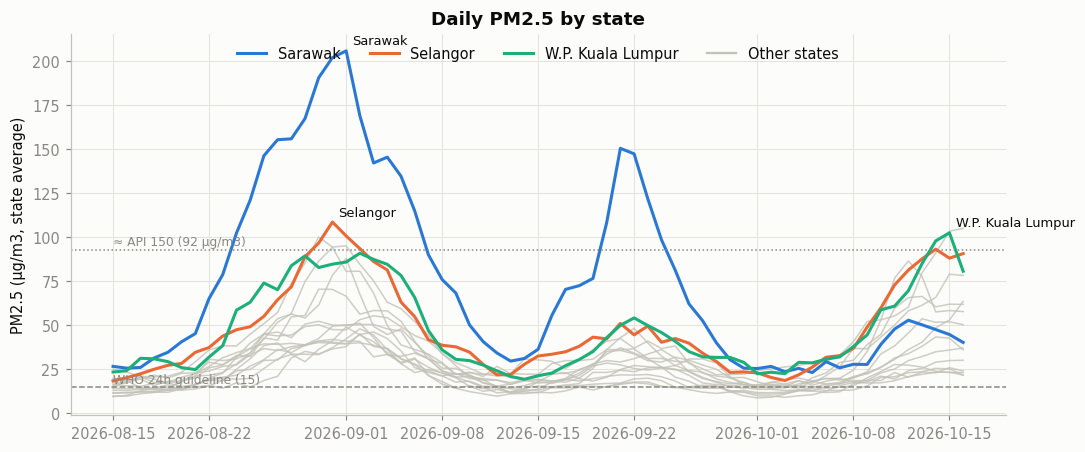

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
highlight = {"Sarawak": SERIES[0], "Selangor": SERIES[1], "W.P. Kuala Lumpur": SERIES[2]}
h = haze.assign(date=pd.to_datetime(haze.date))
for s, g in h.groupby("state"):
    if s not in highlight:
        ax.plot(g.date, g.pm25_ugm3, color=OTHER, lw=1, alpha=0.8)
for s, col in highlight.items():
    g = h[h.state == s]
    ax.plot(g.date, g.pm25_ugm3, color=col, lw=2, label=s)
    i = g.pm25_ugm3.idxmax()
    ax.annotate(s, (g.date[i], g.pm25_ugm3[i]), xytext=(4, 4), textcoords="offset points", color=INK, fontsize=8.5)
ax.axhline(15, color=MUTED, lw=1, ls="--"); ax.text(h.date.min(), 17, "WHO 24h guideline (15)", color=MUTED, fontsize=8)
pm150 = float(policy.api_to_pm25(150))
ax.axhline(pm150, color=MUTED, lw=1, ls=":"); ax.text(h.date.min(), pm150 + 3, f"≈ API 150 ({pm150:.0f} µg/m3)", color=MUTED, fontsize=8)
ax.set_title("Daily PM2.5 by state"); ax.set_ylabel("PM2.5 (µg/m3, state average)")
ax.plot([], [], color=OTHER, label="Other states"); ax.legend(loc="upper center", ncol=4)
plt.tight_layout(); plt.show()

### Days in each API band (worst station in the state)

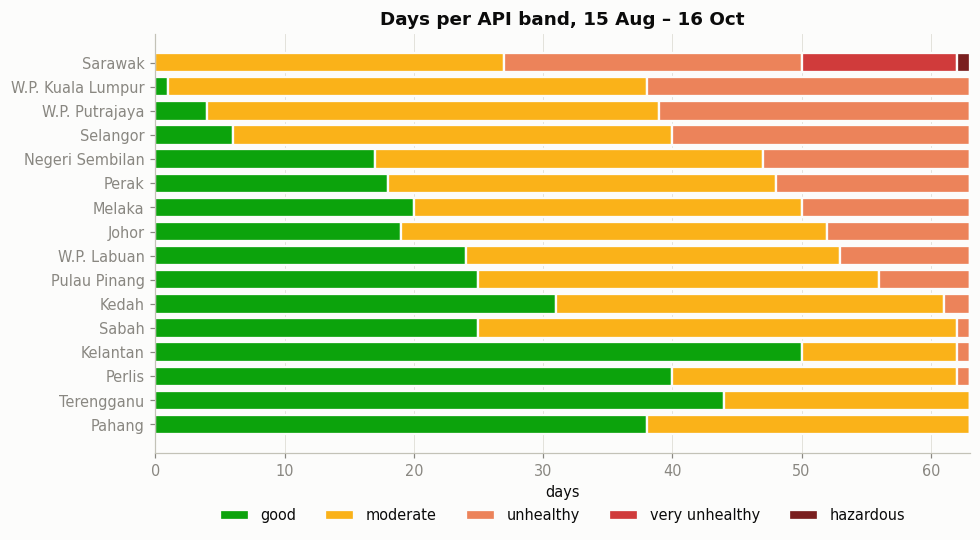

In [8]:
bands = list(BAND_COLOURS)
counts = pd.crosstab(haze.state, haze.api_band).reindex(columns=bands, fill_value=0)
counts = counts.loc[counts[["unhealthy", "very_unhealthy", "hazardous"]].sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(counts))
for b in bands:
    ax.barh(counts.index, counts[b], left=left, color=BAND_COLOURS[b], edgecolor="#fcfcfb", lw=1.5,
            label=b.replace("_", " "))
    left += counts[b].to_numpy()
ax.set_xlabel("days"); ax.set_title("Days per API band, 15 Aug – 16 Oct"); ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

### Mock vs real PM2.5
Only runs if the real Open-Meteo file is in the repo (`data/raw/pm25_daily_openmeteo.csv`, from the Resource Allocation branch).

In [9]:
real, real_path = policy.load_real_pm25()
if real is None:
    print("Real PM2.5 file not found — skipping. Copy pm25_daily_openmeteo.csv into data/raw/ to enable.")
else:
    r = real[real.date >= "2026-08-15"].groupby("state").pm25.agg(["max", "mean"])
    m = mock["haze_daily"].query("date <= @real.date.max()").groupby("state").pm25_ugm3.agg(["max", "mean"])
    cmp_ = r.join(m, lsuffix="_real", rsuffix="_mock").sort_values("max_real")
    fig, ax = plt.subplots(figsize=(8, 5))
    y = np.arange(len(cmp_))
    ax.barh(y + 0.2, cmp_.max_real, height=0.4, color=SERIES[0], label="real (Open-Meteo)")
    ax.barh(y - 0.2, cmp_.max_mock, height=0.4, color=SERIES[1], label="mock")
    ax.set_yticks(y, cmp_.index); ax.set_xlabel("peak PM2.5 (µg/m3)"); ax.legend()
    ax.set_title(f"Peak PM2.5, 15 Aug – {real.date.max()}"); plt.tight_layout(); plt.show()
    corr = np.corrcoef(cmp_.max_real, cmp_.max_mock)[0, 1]
    check("Mock peaks track real peaks (r > 0.8)", corr > 0.8, f"r = {corr:.2f}")

Real PM2.5 file not found — skipping. Copy pm25_daily_openmeteo.csv into data/raw/ to enable.


## 4. Run the damage model

In [10]:
N_SIMS = 1000
result = policy.run(n_sims=N_SIMS, write=False)
nat = result["national"]
print(f"Episode: {result['episode']['start']} → {result['episode']['end']} ({result['episode']['days']} days)")
print(f"National damage: RM {nat['total_damage_rm']/1e9:.2f} bn  "
      f"(90% range RM {nat['ci90_rm'][0]/1e9:.2f}–{nat['ci90_rm'][1]/1e9:.2f} bn)")
print(f"Per day: RM {nat['damage_per_day_rm']/1e6:.0f} m   (published estimate: RM 20–50 m/day)")
pd.DataFrame([{"state": s["state"], "damage_rm_m": s["damage_to_date_rm"] / 1e6, "pct_gdp": s["damage_pct_gdp"],
               **{f"forecast_{h}h_rm_m": v / 1e6 for h, v in s["forecast_damage_rm"].items()}}
              for s in result["states"]]).round(2)

[warn] data\mock\damage is from an older version (missing ['flights_scheduled', 'school_closed_share', 'stations_over_200']); using freshly generated mock data instead. Re-save with --save-mock to update the CSVs.


Episode: 2026-08-15 → 2026-10-16 (63 days)
National damage: RM 1.47 bn  (90% range RM 1.12–2.40 bn)
Per day: RM 23 m   (published estimate: RM 20–50 m/day)


,state,damage_rm_m,pct_gdp,forecast_24h_rm_m,forecast_48h_rm_m,forecast_72h_rm_m
0,Sarawak,428.42,0.28,0.03,0.03,0.03
1,Selangor,408.88,0.10,18.84,18.84,18.84
2,W.P. Kuala Lumpur,310.01,0.11,12.79,12.79,12.79
3,Johor,98.62,0.06,8.88,8.88,8.88
4,Perak,81.55,0.09,4.82,4.82,4.82
5,Negeri Sembilan,41.84,0.08,2.60,2.60,2.60
6,Pulau Pinang,36.51,0.03,5.16,5.16,5.16
7,Melaka,33.37,0.07,2.56,2.56,2.56
8,W.P. Putrajaya,10.25,0.07,0.46,0.46,0.46
9,Sabah,7.11,0.01,0.01,0.01,0.01


## 5. Output checks

In [11]:
states = result["states"]
cats = policy.CATEGORIES
state_keys = {"state", "lat", "lon", "population", "damage_to_date_rm", "by_category_rm",
              "damage_pct_gdp", "forecast_damage_rm", "api_latest"}
check("Top-level fields present", {"episode", "national", "states", "model", "assumptions"} <= set(result))
check("Every state has every field", all(state_keys <= set(s) for s in states))
check("16 states in the output", len(states) == 16)
check("Every state has all 8 categories", all(set(s["by_category_rm"]) == set(cats) for s in states))
check("No negative costs", all(v >= 0 for s in states for v in s["by_category_rm"].values()))
check("Categories add up to each state's total",
      all(abs(sum(s["by_category_rm"].values()) - s["damage_to_date_rm"]) <= len(cats) for s in states))
check("States add up to the national total",
      abs(sum(s["damage_to_date_rm"] for s in states) - nat["total_damage_rm"]) <= len(states))
check("National total inside its 90% range", nat["ci90_rm"][0] <= nat["total_damage_rm"] <= nat["ci90_rm"][1])
check("Forecast has 24/48/72h for every state", all(set(s["forecast_damage_rm"]) == {"24", "48", "72"} for s in states))
check("Every assumption has a source", all(str(a["source"]).strip() for a in result["assumptions"]))
dummy = {k for k, v in policy.COEFFS.items() if "DUMMY" in v["source"]}
flagged = {a["name"] for a in result["assumptions"] if "DUMMY" in str(a["source"])}
check("Dummy values are labelled as dummy", dummy <= flagged, f"{len(dummy)} coefficients still dummy")
check("Mortality excluded (haze treated as non-fatal)", nat["by_category_rm"]["mortality"] == 0)
check("Backtest scores filled in", result["model"]["backtest_mape"] is not None)
if policy.STATES_JSON.exists():
    import json
    theirs = {s["state"] for s in json.loads(policy.STATES_JSON.read_text())["states"]}
    check("State names match Resource Allocation's states.json", theirs == set(policy.STATE_NAMES))
else:
    print("SKIP  states.json not in data/out yet")

PASS  Top-level fields present
PASS  Every state has every field
PASS  16 states in the output
PASS  Every state has all 8 categories
PASS  No negative costs
PASS  Categories add up to each state's total
PASS  States add up to the national total
PASS  National total inside its 90% range
PASS  Forecast has 24/48/72h for every state
PASS  Every assumption has a source
PASS  Dummy values are labelled as dummy  —  19 coefficients still dummy
PASS  Mortality excluded (haze treated as non-fatal)
PASS  Backtest scores filled in
SKIP  states.json not in data/out yet


## 6. Results

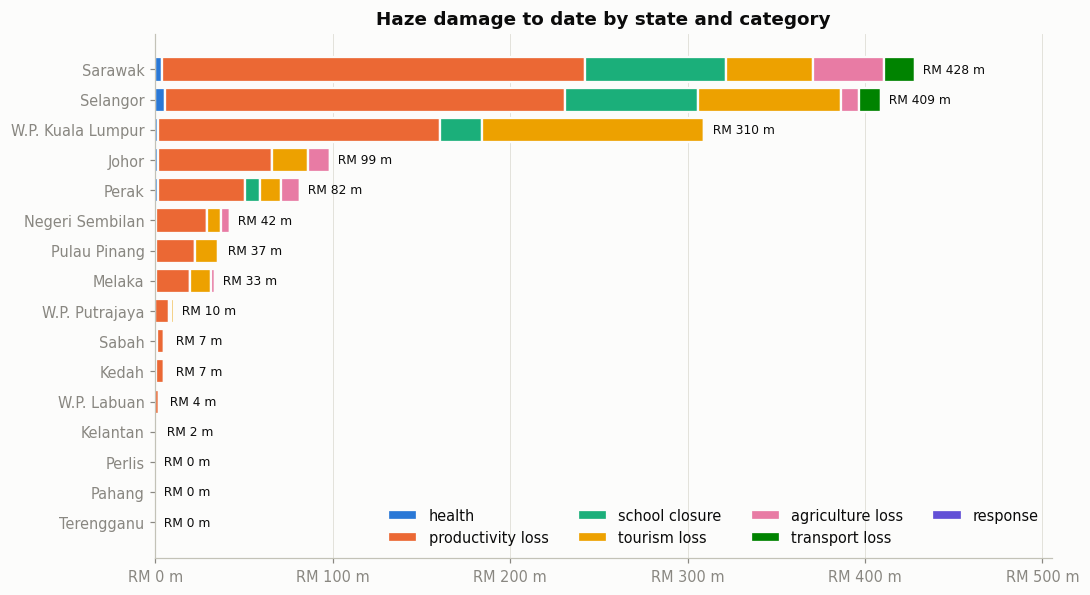

In [12]:
# Damage by state, stacked by category (mortality omitted — it is 0)
show = [c for c in cats if nat["by_category_rm"][c] > 0]
df = pd.DataFrame([{**s["by_category_rm"], "state": s["state"]} for s in states]).set_index("state")[show]
df = df.loc[df.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(df))
for i, c in enumerate(show):
    ax.barh(df.index, df[c], left=left, color=SERIES[i], edgecolor="#fcfcfb", lw=1.5, label=c.replace("_", " "))
    left += df[c].to_numpy()
for y, v in enumerate(left):
    ax.text(v, y, f"  RM {v/1e6:,.0f} m", va="center", fontsize=8, color=INK)
ax.xaxis.set_major_formatter(rm_m); ax.grid(axis="y", visible=False)
ax.set_title("Haze damage to date by state and category")
ax.legend(ncol=4, loc="lower right")
ax.set_xlim(0, left.max() * 1.18); plt.tight_layout(); plt.show()

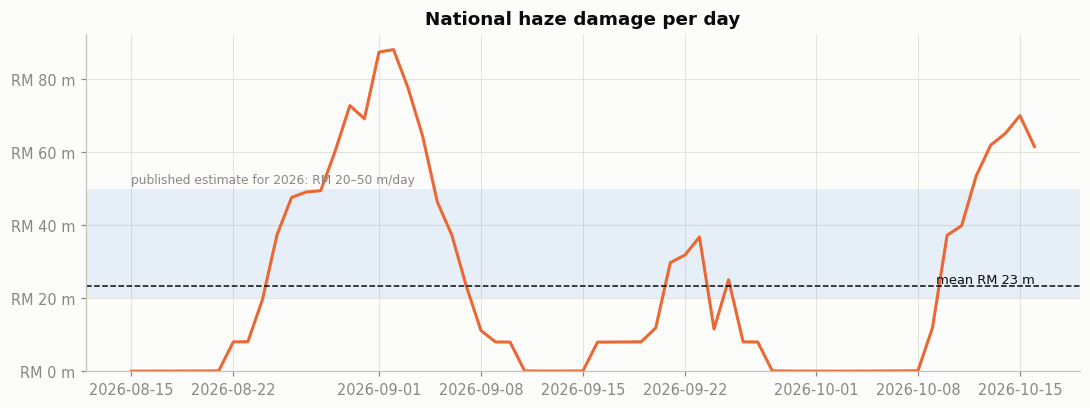

In [13]:
# National damage per day vs the published RM 20–50 m/day estimate
daily = policy.damage_by_day(haze, ref, policy.central())
nd = daily.groupby("date").total_damage_rm.sum()
nd.index = pd.to_datetime(nd.index)
lo, hi = result["model"]["benchmark_rm_per_day"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhspan(lo, hi, color=SERIES[0], alpha=0.10, lw=0)
ax.text(nd.index.min(), hi * 1.03, "published estimate for 2026: RM 20–50 m/day", color=MUTED, fontsize=8)
ax.plot(nd.index, nd.values, color=SERIES[1], lw=2)
ax.axhline(nd.mean(), color=INK, lw=1, ls="--")
ax.text(nd.index.max(), nd.mean(), f" mean RM {nd.mean()/1e6:.0f} m", va="bottom", ha="right", fontsize=8.5)
ax.yaxis.set_major_formatter(rm_m); ax.set_title("National haze damage per day"); ax.set_ylim(0)
plt.tight_layout(); plt.show()

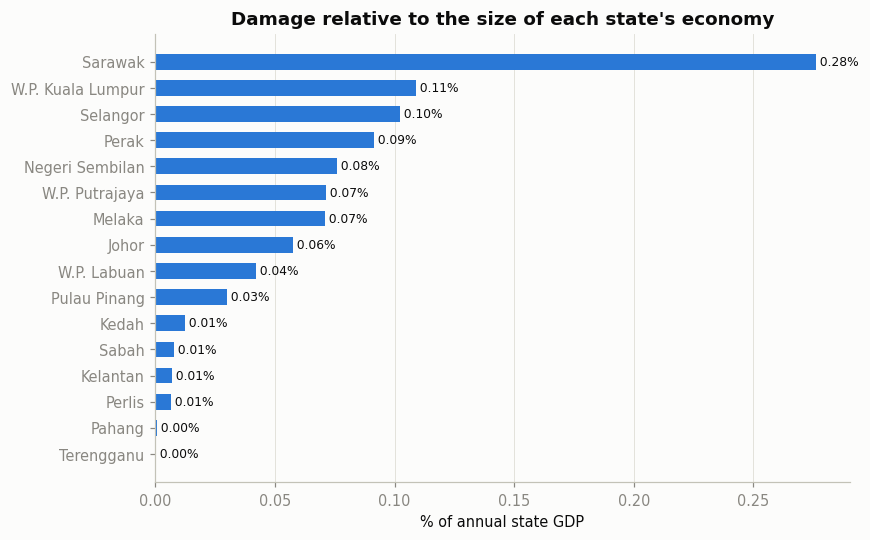

In [14]:
# Damage as % of each state's annual GDP
pct = pd.Series({s["state"]: s["damage_pct_gdp"] for s in states}).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pct.index, pct.values, color=SERIES[0], height=0.6)
for y, v in enumerate(pct.values):
    ax.text(v, y, f" {v:.2f}%", va="center", fontsize=8)
ax.set_xlabel("% of annual state GDP"); ax.grid(axis="y", visible=False)
ax.set_title("Damage relative to the size of each state's economy"); plt.tight_layout(); plt.show()

## 7. Behaviour checks

PASS  Clean air (PM2.5 10, API ~40) costs nothing  —  RM 0
PASS  Damage never falls as PM2.5 rises
PASS  Damage rises between clean and unhealthy air
PASS  Health cost rises smoothly with PM2.5


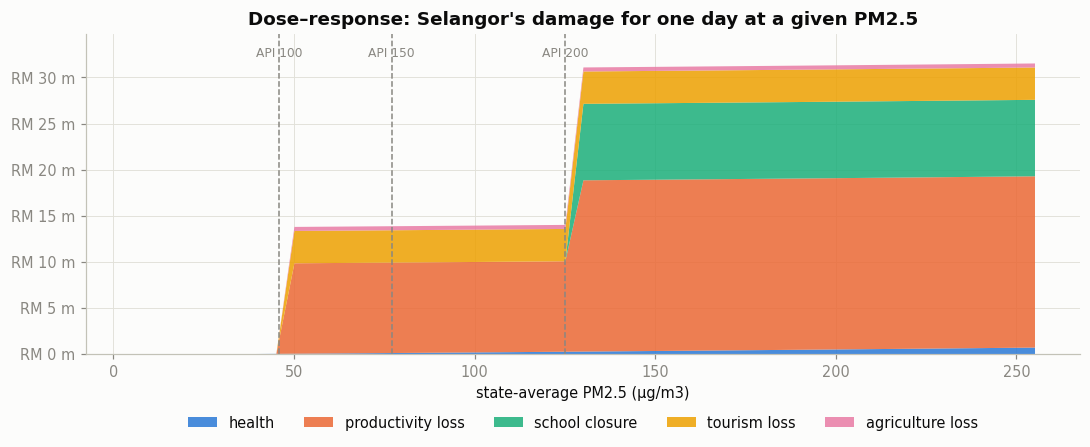

Steps = API thresholds where absences, tourism/agri losses and school closures kick in; health rises smoothly.


In [15]:
def one_day(pm25, state=None):
    """One synthetic day at a fixed PM2.5 for every state (or one state)."""
    api_avg = float(policy.pm25_to_api(pm25)); api_worst = float(policy.pm25_to_api(pm25 * 1.2))
    d = pd.DataFrame({"date": "2026-01-01", "state": ref.state, "pm25_ugm3": pm25, "api_mean": api_avg,
                      "api_max": api_worst, "school_closed_share": 0.5 if api_worst > 200 else 0.0,
                      "school_closed": int(api_worst > 200), "flights_disrupted": 0, "cloud_seeding_ops": 0})
    return d if state is None else d[d.state == state]

c0 = policy.central()
clean = policy.damage_by_day(one_day(10), ref, c0).total_damage_rm.sum()
check("Clean air (PM2.5 10, API ~40) costs nothing", abs(clean) < 1, f"RM {clean:,.0f}")

grid = np.arange(5, 260, 5)
curve = pd.DataFrame([policy.damage_by_day(one_day(p, "Selangor"), ref, c0)[cats].sum() for p in grid], index=grid)
total = curve.sum(axis=1)
check("Damage never falls as PM2.5 rises", (np.diff(total.to_numpy()) >= -1).all())
check("Damage rises between clean and unhealthy air", total.loc[100] > total.loc[20] > total.loc[5])
check("Health cost rises smoothly with PM2.5", (np.diff(curve.health.to_numpy()) > 0)[2:].all())

fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(grid))
for i, c in enumerate([c for c in cats if curve[c].max() > 0]):
    ax.fill_between(grid, bottom, bottom + curve[c], color=SERIES[i], alpha=0.85, lw=0, label=c.replace("_", " "))
    bottom += curve[c].to_numpy()
for a in (100, 150, 200):
    x = float(policy.api_to_pm25(a) / 1.2)   # state average at which the worst station typically reaches API a
    ax.axvline(x, color=MUTED, lw=1, ls="--"); ax.text(x, bottom.max() * 1.02, f"API {a}", color=MUTED, fontsize=8, ha="center")
ax.yaxis.set_major_formatter(rm_m); ax.set_xlabel("state-average PM2.5 (µg/m3)")
ax.set_title("Dose–response: Selangor's damage for one day at a given PM2.5")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15)); ax.set_ylim(0, bottom.max() * 1.1)
plt.tight_layout(); plt.show()
print("Steps = API thresholds where absences, tourism/agri losses and school closures kick in; health rises smoothly.")

## 8. Uncertainty (Monte Carlo)

PASS  90% range is not absurdly wide (95th < 3× 5th)  —  RM 1.12–2.40 bn


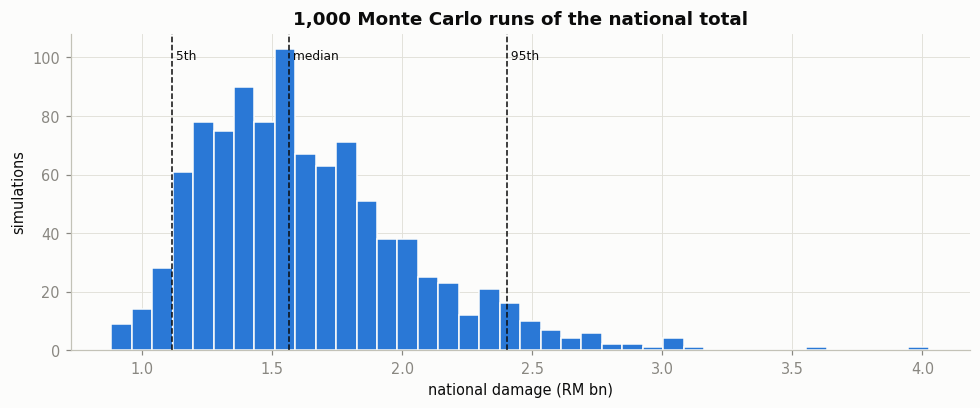

In [16]:
draws = policy.monte_carlo(haze, ref, N_SIMS).sum(axis=1)
p5, p50, p95 = np.percentile(draws, [5, 50, 95])
check("90% range is not absurdly wide (95th < 3× 5th)", p95 < 3 * p5, f"RM {p5/1e9:.2f}–{p95/1e9:.2f} bn")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(draws / 1e9, bins=40, color=SERIES[0], edgecolor="#fcfcfb", lw=1)
for v, lab in [(p5, "5th"), (p50, "median"), (p95, "95th")]:
    ax.axvline(v / 1e9, color=INK, lw=1, ls="--"); ax.text(v / 1e9, ax.get_ylim()[1] * 0.92, f" {lab}", fontsize=8)
ax.set_xlabel("national damage (RM bn)"); ax.set_ylabel("simulations")
ax.set_title(f"{N_SIMS:,} Monte Carlo runs of the national total"); plt.tight_layout(); plt.show()

## 9. Sensitivity — which assumptions matter most

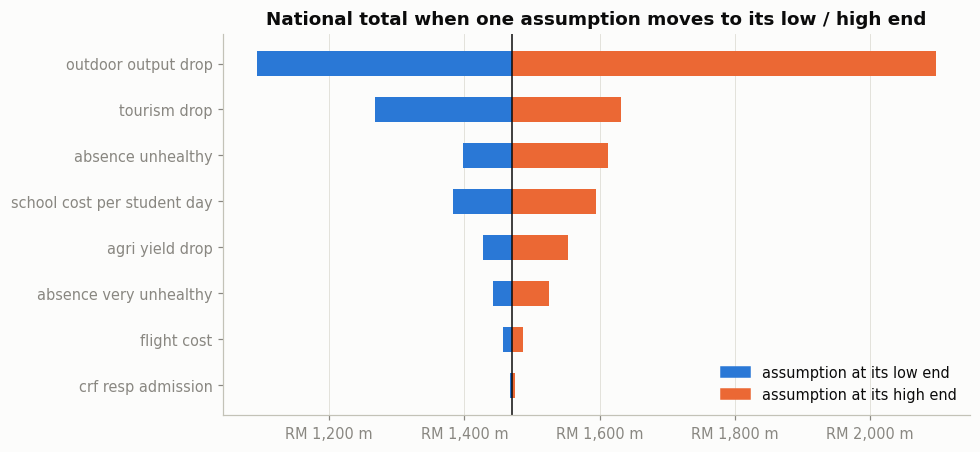

,coefficient,swing_rm_m
0,outdoor_output_drop,1004.0
1,tourism_drop,365.0
2,absence_unhealthy,215.0
3,school_cost_per_student_day,212.0
4,agri_yield_drop,125.0
5,absence_very_unhealthy,83.0
6,flight_cost,29.0
7,crf_resp_admission,8.0


In [17]:
tor = policy.sensitivity(haze, ref, top=8).iloc[::-1]
base = nat["total_damage_rm"]
fig, ax = plt.subplots(figsize=(9, 4.2))
for y, r in enumerate(tor.itertuples()):
    lo_, hi_ = sorted([r.low_rm, r.high_rm])
    ax.barh(y, lo_ - base, left=base, color=SERIES[0], height=0.55)
    ax.barh(y, hi_ - base, left=base, color=SERIES[1], height=0.55)
ax.axvline(base, color=INK, lw=1)
ax.set_yticks(range(len(tor)), tor.coefficient.str.replace("_", " ")); ax.xaxis.set_major_formatter(rm_m)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES[0], label="assumption at its low end"),
                   Patch(color=SERIES[1], label="assumption at its high end")], loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("National total when one assumption moves to its low / high end"); plt.tight_layout(); plt.show()
tor.iloc[::-1].assign(swing_rm_m=lambda d: (d.swing_rm / 1e6).round(0))[["coefficient", "swing_rm_m"]]

## 10. Backtest vs mock truth
⚠️ The mock "truth" was generated with the same formulas (plus noise), so a low error here only shows the code
is consistent — it is **not** evidence the model is right. Section 11 is the real sanity check.

PASS  Damage function beats the PM2.5-only baseline  —  MAPE 5.5% vs baseline 2073.5%


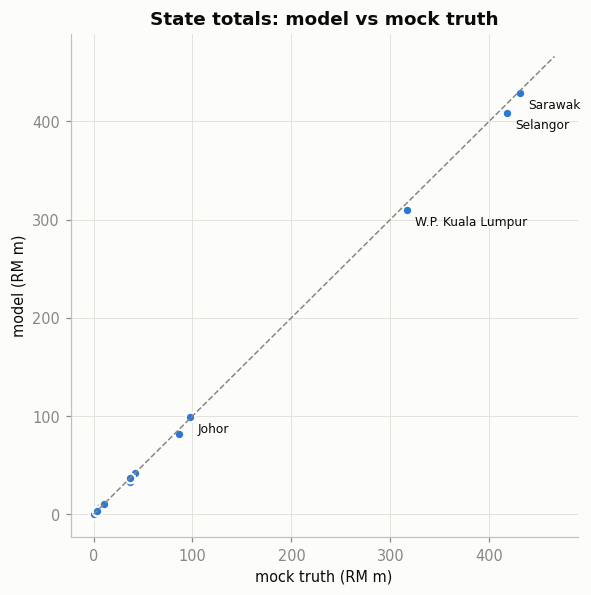

In [18]:
m_haze, m_ref, m_truth = mock["haze_daily"], mock["state_reference"], mock["damage_costs_daily"]
pred = policy.damage_by_day(m_haze, m_ref, c0).groupby("state").total_damage_rm.sum()
act = m_truth.groupby("state").total_damage_rm.sum()
bt = result["model"]
check("Damage function beats the PM2.5-only baseline", bt["backtest_mape"] < bt["baseline_mape"],
      f"MAPE {bt['backtest_mape']:.1%} vs baseline {bt['baseline_mape']:.1%}")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(act / 1e6, pred.reindex(act.index) / 1e6, s=40, color=SERIES[0], edgecolor="#fcfcfb", lw=1.5)
lim = max(act.max(), pred.max()) / 1e6 * 1.08
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--")
for s in act.nlargest(4).index:
    ax.annotate(s, (act[s] / 1e6, pred[s] / 1e6), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.set_xlabel("mock truth (RM m)"); ax.set_ylabel("model (RM m)")
ax.set_title("State totals: model vs mock truth"); plt.tight_layout(); plt.show()

## 11. Realism check vs published estimates

PASS  Within the published 2026 range (RM 20–50 m/day)  —  RM 23 m/day
PASS  Same order of magnitude as the 2013 haze (0.3×–3×)  —  0.9× 2013
PASS  Health costs don't dominate (haze mostly costs the economy)


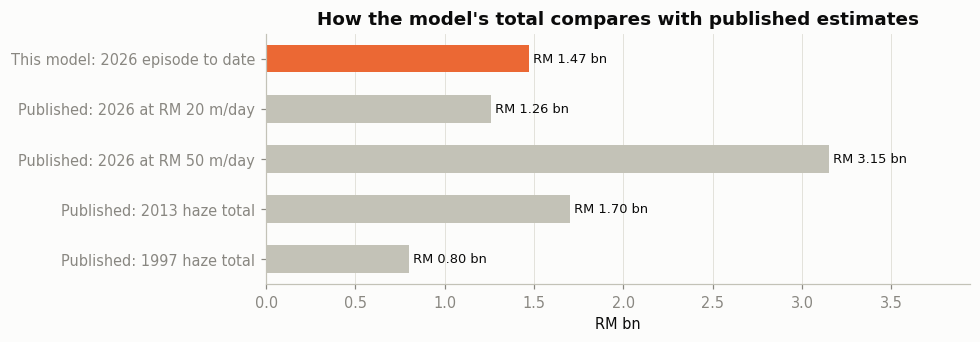

Sources: The Star, 14 Oct 2026 (Yeah Kim Leng); MJPHM literature review (2013 haze).


In [19]:
B = policy.BENCHMARKS
days = result["episode"]["days"]
rows = [
    ("This model: 2026 episode to date", nat["total_damage_rm"]),
    ("Published: 2026 at RM 20 m/day", B["2026_daily_low_rm"] * days),
    ("Published: 2026 at RM 50 m/day", B["2026_daily_high_rm"] * days),
    ("Published: 2013 haze total", B["2013_total_rm"]),
    ("Published: 1997 haze total", B["1997_total_rm"]),
]
bench = pd.DataFrame(rows, columns=["estimate", "rm"]).set_index("estimate")
check("Within the published 2026 range (RM 20–50 m/day)",
      B["2026_daily_low_rm"] <= nat["damage_per_day_rm"] <= B["2026_daily_high_rm"],
      f"RM {nat['damage_per_day_rm']/1e6:.0f} m/day")
check("Same order of magnitude as the 2013 haze (0.3×–3×)",
      0.3 <= nat["total_damage_rm"] / B["2013_total_rm"] <= 3, f"{nat['total_damage_rm']/B['2013_total_rm']:.1f}× 2013")
check("Health costs don't dominate (haze mostly costs the economy)",
      nat["by_category_rm"]["health"] < 0.25 * nat["total_damage_rm"])
fig, ax = plt.subplots(figsize=(9, 3.2))
cols = [SERIES[1]] + [OTHER] * (len(bench) - 1)
ax.barh(bench.index[::-1], bench.rm[::-1] / 1e9, color=cols[::-1], height=0.55)
for y, v in enumerate(bench.rm[::-1] / 1e9):
    ax.text(v, y, f" RM {v:.2f} bn", va="center", fontsize=8.5)
ax.set_xlabel("RM bn"); ax.grid(axis="y", visible=False); ax.set_xlim(0, bench.rm.max() / 1e9 * 1.25)
ax.set_title("How the model's total compares with published estimates"); plt.tight_layout(); plt.show()
print("Sources: The Star, 14 Oct 2026 (Yeah Kim Leng); MJPHM literature review (2013 haze).")

## 12. Test summary

In [20]:
summary = pd.DataFrame(RESULTS)
n_fail = (summary.result == "FAIL").sum()
print(f"{len(summary) - n_fail} passed, {n_fail} failed")
display(summary.style.map(lambda v: "color:#d03b3b;font-weight:bold" if v == "FAIL" else "", subset=["result"]))
assert n_fail == 0, f"{n_fail} check(s) failed — see the table above"

33 passed, 0 failed


,test,result,detail
0,All 16 states in the state table,PASS,16 states
1,All 16 states in the haze table,PASS,
2,No missing values (state table),PASS,
3,No missing values (haze table),PASS,
4,One row per state per day,PASS,
5,No gaps in the dates,PASS,15 Aug → 16 Oct 2026
6,PM2.5 within 0–500 µg/m3,PASS,max 206
7,API within 0–500,PASS,
8,Worst station API ≥ state average API,PASS,
9,School-closure share within 0–1,PASS,
